# Problema 6 — Data Bias (Sesgo en los datos)
## Dataset: Base 2 — Matrícula y secciones 2023

**Qué vamos a aprender:**
1. Cómo una métrica global puede ocultar fallos catastróficos en subgrupos
2. Cómo desagregar métricas por variable protegida
3. Qué son las métricas de equidad: Demographic Parity, Equal Opportunity, Equalized Odds
4. Cómo detectar y documentar bias de forma operativa

### El contexto
En políticas educativas, un modelo que funciona bien "en promedio" puede estar fallando
sistemáticamente en un subgrupo (ej: escuelas rurales, escuelas privadas pequeñas).
Esto tiene implicancias éticas y de política pública muy graves.

Vamos a **provocar el bias deliberadamente** para demostrar cómo aparece y cómo detectarlo.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score
)

np.random.seed(42)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)

ARCHIVO = 'data/matricula_secciones_2023.csv'
df_raw = pd.read_csv(ARCHIVO, sep=';', encoding='utf-8-sig', low_memory=False)

mat_cols = [c for c in ['_1','_2','_3','_4','_5','_6','_7','_8','_9','_10','_11','_12','_1314','_snu'] if c in df_raw.columns]
rep_cols = [c for c in ['r_1','r_2','r_3','r_4','r_5','r_6','r_7','r_8','r_9','r_10','r_11','r_12','r_1314','r_20'] if c in df_raw.columns]
sec_cols = [c for c in ['_sec1','_sec2','_sec3','_sec4','_sec5','_sec6','_sec7','_sec8','_sec9','_sec10','_sec11','_sec12','_sec1314','_sec20'] if c in df_raw.columns]

df = df_raw.copy()
df['matricula_total']   = df[mat_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['repetidores_total'] = df[rep_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)
df['secciones_total']   = df[sec_cols].apply(pd.to_numeric, errors='coerce').sum(axis=1, min_count=1)

df = df[(df['matricula_total'] > 0) & df['repetidores_total'].notna()].copy()
df['tasa_repitencia'] = df['repetidores_total'] / df['matricula_total']

UMBRAL = 0.12
df['alta_repitencia'] = (df['tasa_repitencia'] > UMBRAL).astype(int)

print(f'Escuelas: {len(df):,}')
print(f'Target: alta_repitencia (>{UMBRAL*100:.0f}%)')
print(f'  Clase 0: {(df["alta_repitencia"]==0).sum():,}')
print(f'  Clase 1: {(df["alta_repitencia"]==1).sum():,}')

print(f'\nDistribución por ámbito (variable a evaluar):')
print(df['ambito'].value_counts())

Escuelas: 35,169
Target: alta_repitencia (>12%)
  Clase 0: 31,466
  Clase 1: 3,703

Distribución por ámbito (variable a evaluar):
ambito
Urbano    21825
Rural     13340
Name: count, dtype: int64


## 1. Provocar bias: dataset con representación desigual

Simulamos que al recolectar datos el equipo subrepresentó un subgrupo.
Conservamos solo el 20% de las escuelas rurales (o el grupo minoritario en `ambito`) en training,
pero evaluamos en el test completo.

In [2]:
# Identificar el grupo minoritario en ámbito
grupos = df['ambito'].value_counts()
print(f'Grupos en ambito: {grupos.to_dict()}')

# Asumimos que el grupo mayoritario es "Urbano" y el minoritario es "Rural" o similar
if 'Rural' in df['ambito'].unique():
    GRUPO_A = [v for v in df['ambito'].unique() if v != 'Rural']
    GRUPO_A = GRUPO_A[0] if GRUPO_A else grupos.index[0]
    GRUPO_B = 'Rural'
else:
    GRUPO_A = grupos.index[0]  # mayoritario
    GRUPO_B = grupos.index[1] if len(grupos) > 1 else grupos.index[0]  # minoritario

print(f'\nGrupo A (mayoritario): "{GRUPO_A}" — {(df["ambito"]==GRUPO_A).sum():,} escuelas')
print(f'Grupo B (minoritario): "{GRUPO_B}" — {(df["ambito"]==GRUPO_B).sum():,} escuelas')

# Tasa de repitencia alta por grupo (baseline real)
print(f'\nTasa base de alta_repitencia por grupo:')
print(f'  Grupo A: {df[df["ambito"]==GRUPO_A]["alta_repitencia"].mean():.3f}')
print(f'  Grupo B: {df[df["ambito"]==GRUPO_B]["alta_repitencia"].mean():.3f}')

Grupos en ambito: {'Urbano': 21825, 'Rural': 13340}

Grupo A (mayoritario): "Urbano" — 21,825 escuelas
Grupo B (minoritario): "Rural" — 13,340 escuelas

Tasa base de alta_repitencia por grupo:
  Grupo A: 0.102
  Grupo B: 0.111


In [3]:
# Features simples (no usar tasa_repitencia para evitar leakage)
FEATURES = ['matricula_total', 'secciones_total', 'provincia', 'sector', 'ambito']
num_cols = ['matricula_total', 'secciones_total']
cat_cols = ['provincia', 'sector', 'ambito']

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
])

# Split representativo estándar
X = df[FEATURES].copy()
y = df['alta_repitencia'].values
amb = df['ambito'].values

X_train, X_test, y_train, y_test, amb_train, amb_test = train_test_split(
    X, y, amb, test_size=0.25, random_state=42, stratify=y
)

print(f'Train representativo: {len(X_train):,} escuelas')
print(f'Test:                  {len(X_test):,} escuelas')

Train representativo: 26,376 escuelas
Test:                  8,793 escuelas


## 2. Modelo A — entrenado con datos representativos (baseline)

In [4]:
pipe_fair = Pipeline([('pre', pre), ('model', GradientBoostingClassifier(n_estimators=100, random_state=42))])
pipe_fair.fit(X_train, y_train)

y_pred_fair = pipe_fair.predict(X_test)
y_proba_fair = pipe_fair.predict_proba(X_test)[:, 1]

def metricas_globales(nombre, y_true, y_pred, y_proba):
    print(f'\n=== {nombre} — métricas GLOBALES ===')
    print(f'  Accuracy:  {accuracy_score(y_true, y_pred):.4f}')
    print(f'  Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'  Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'  F1:        {f1_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'  AUC-ROC:   {roc_auc_score(y_true, y_proba):.4f}')

metricas_globales('Modelo A (entrenado representativamente)', y_test, y_pred_fair, y_proba_fair)


=== Modelo A (entrenado representativamente) — métricas GLOBALES ===
  Accuracy:  0.8947
  Precision: 0.0000
  Recall:    0.0000
  F1:        0.0000
  AUC-ROC:   0.7273


## 3. Modelo B — entrenado con datos SESGADOS (subrepresentación del Grupo B)

In [5]:
# Crear training sesgado: conservar solo 20% de las escuelas del Grupo B
rng = np.random.RandomState(42)
mask_B = amb_train == GRUPO_B
mask_A = ~mask_B

idx_B = np.where(mask_B)[0]
keep_B = rng.choice(idx_B, size=int(0.2 * len(idx_B)), replace=False)
idx_A = np.where(mask_A)[0]

keep = np.concatenate([idx_A, keep_B])
keep.sort()

X_train_biased = X_train.iloc[keep].reset_index(drop=True)
y_train_biased = y_train[keep]

print(f'Training SESGADO:')
print(f'  Grupo A ({GRUPO_A}): {(X_train_biased["ambito"]==GRUPO_A).sum():,}')
print(f'  Grupo B ({GRUPO_B}): {(X_train_biased["ambito"]==GRUPO_B).sum():,}')
print(f'  Total: {len(X_train_biased):,}')

# Entrenar modelo sesgado
pipe_biased = Pipeline([('pre', pre), ('model', GradientBoostingClassifier(n_estimators=100, random_state=42))])
pipe_biased.fit(X_train_biased, y_train_biased)

y_pred_biased = pipe_biased.predict(X_test)
y_proba_biased = pipe_biased.predict_proba(X_test)[:, 1]

metricas_globales('Modelo B (entrenado con datos sesgados)', y_test, y_pred_biased, y_proba_biased)
print()
print('Las métricas globales son similares — NO revelan el bias.')

Training SESGADO:
  Grupo A (Urbano): 16,353
  Grupo B (Rural): 2,004
  Total: 18,359



=== Modelo B (entrenado con datos sesgados) — métricas GLOBALES ===
  Accuracy:  0.8947
  Precision: 0.0000
  Recall:    0.0000
  F1:        0.0000
  AUC-ROC:   0.7183

Las métricas globales son similares — NO revelan el bias.


## 4. Desagregación por subgrupo — donde aparece el bias

In [6]:
def metricas_por_grupo(y_true, y_pred, y_proba, grupos, nombre_modelo):
    """Calcula métricas para cada subgrupo."""
    resultados = []
    for g in pd.Series(grupos).dropna().unique():  # se excluyen escuelas sin ámbito informado
        mask = grupos == g
        if mask.sum() < 10:
            continue
        yt = y_true[mask]
        yp = y_pred[mask]
        ypr = y_proba[mask]
        resultados.append({
            'Modelo': nombre_modelo,
            'Grupo': g,
            'N': int(mask.sum()),
            'Accuracy':  accuracy_score(yt, yp),
            'Precision': precision_score(yt, yp, zero_division=0),
            'Recall':    recall_score(yt, yp, zero_division=0),
            'F1':        f1_score(yt, yp, zero_division=0),
            'AUC':       roc_auc_score(yt, ypr) if len(np.unique(yt)) > 1 else np.nan,
            'TasaPosPred': yp.mean(),
            'TasaPosReal': yt.mean()
        })
    return pd.DataFrame(resultados)

res_A = metricas_por_grupo(y_test, y_pred_fair,   y_proba_fair,   amb_test, 'A (fair)')
res_B = metricas_por_grupo(y_test, y_pred_biased, y_proba_biased, amb_test, 'B (biased)')

todo = pd.concat([res_A, res_B]).reset_index(drop=True)
print('Métricas desagregadas por ámbito:\n')
print(todo.round(4).to_string(index=False))

Métricas desagregadas por ámbito:

    Modelo  Grupo    N  Accuracy  Precision  Recall  F1    AUC  TasaPosPred  TasaPosReal
  A (fair) Urbano 5472    0.8982        0.0     0.0 0.0 0.7567          0.0       0.1018
  A (fair)  Rural 3319    0.8891        0.0     0.0 0.0 0.6731          0.0       0.1109
B (biased) Urbano 5472    0.8982        0.0     0.0 0.0 0.7536          0.0       0.1018
B (biased)  Rural 3319    0.8891        0.0     0.0 0.0 0.6546          0.0       0.1109



Recall en el GRUPO Rural (minoritario):
  Modelo A (fair):   0.0000
  Modelo B (biased): 0.0000
  Diferencia:        +0.0000

Recall en el GRUPO Urbano (mayoritario):
  Modelo A (fair):   0.0000
  Modelo B (biased): 0.0000


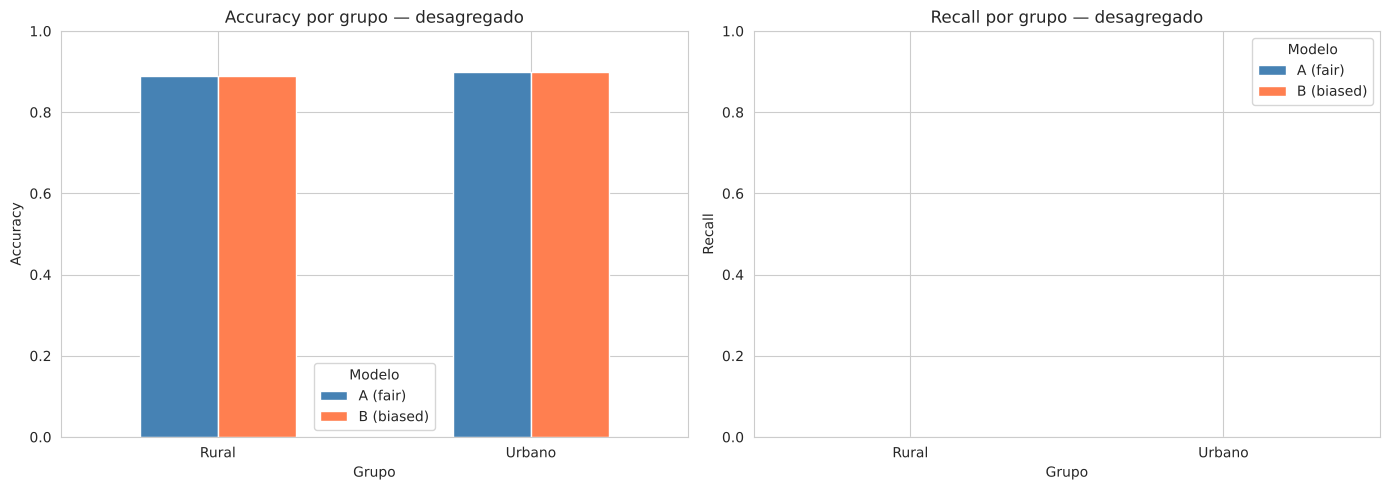

In [7]:
# Comparar el recall del grupo minoritario entre los dos modelos
recall_fair_B = res_A[res_A['Grupo']==GRUPO_B]['Recall'].values[0]
recall_biased_B = res_B[res_B['Grupo']==GRUPO_B]['Recall'].values[0]

recall_fair_A = res_A[res_A['Grupo']==GRUPO_A]['Recall'].values[0]
recall_biased_A = res_B[res_B['Grupo']==GRUPO_A]['Recall'].values[0]

print(f'\nRecall en el GRUPO {GRUPO_B} (minoritario):')
print(f'  Modelo A (fair):   {recall_fair_B:.4f}')
print(f'  Modelo B (biased): {recall_biased_B:.4f}')
print(f'  Diferencia:        {recall_fair_B - recall_biased_B:+.4f}')
print()
print(f'Recall en el GRUPO {GRUPO_A} (mayoritario):')
print(f'  Modelo A (fair):   {recall_fair_A:.4f}')
print(f'  Modelo B (biased): {recall_biased_A:.4f}')

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metrica in zip(axes, ['Accuracy', 'Recall']):
    pivot = todo.pivot(index='Grupo', columns='Modelo', values=metrica)
    pivot.plot(kind='bar', ax=ax, color=['steelblue', 'coral'], edgecolor='white')
    ax.set_title(f'{metrica} por grupo — desagregado')
    ax.set_ylabel(metrica)
    ax.set_ylim(0, 1)
    ax.legend(title='Modelo')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 5. Métricas formales de equidad (fairness metrics)

### Demographic Parity
$$P(\hat{Y}=1 | A) = P(\hat{Y}=1 | B)$$

La proporción de predicciones positivas debe ser igual en cada grupo.

### Equal Opportunity
$$P(\hat{Y}=1 | Y=1, A) = P(\hat{Y}=1 | Y=1, B)$$

El recall (TPR) debe ser igual en cada grupo.

### Equalized Odds
$$TPR_A = TPR_B \quad \text{AND} \quad FPR_A = FPR_B$$

Tanto TPR como FPR deben ser iguales entre grupos.

In [8]:
def fairness_metrics(y_true, y_pred, grupos, group_a, group_b):
    """Calcula métricas de equidad entre dos grupos."""
    def por_grupo(mask):
        yt = y_true[mask]
        yp = y_pred[mask]
        if len(np.unique(yt)) < 2:
            return np.nan, np.nan, yp.mean()
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        return tpr, fpr, yp.mean()

    tpr_a, fpr_a, pr_a = por_grupo(grupos == group_a)
    tpr_b, fpr_b, pr_b = por_grupo(grupos == group_b)

    return {
        'Demographic Parity':     f'{pr_a:.3f} vs {pr_b:.3f} (diff={pr_a-pr_b:+.3f})',
        'Equal Opportunity (TPR)': f'{tpr_a:.3f} vs {tpr_b:.3f} (diff={tpr_a-tpr_b:+.3f})',
        'FPR':                    f'{fpr_a:.3f} vs {fpr_b:.3f} (diff={fpr_a-fpr_b:+.3f})'
    }

print(f'Comparación de Grupo A = "{GRUPO_A}" vs. Grupo B = "{GRUPO_B}"\n')

print('=== Modelo A (representativo) ===')
for k, v in fairness_metrics(y_test, y_pred_fair, amb_test, GRUPO_A, GRUPO_B).items():
    print(f'  {k}: {v}')

print('\n=== Modelo B (sesgado) ===')
for k, v in fairness_metrics(y_test, y_pred_biased, amb_test, GRUPO_A, GRUPO_B).items():
    print(f'  {k}: {v}')

print('\n💡 La diferencia (diff) es el indicador de inequidad.')
print('  Valores absolutos > 0.10 sugieren intervención necesaria.')
print('  Valores > 0.20 son indicadores graves de bias del modelo.')

Comparación de Grupo A = "Urbano" vs. Grupo B = "Rural"

=== Modelo A (representativo) ===


  Demographic Parity: 0.000 vs 0.000 (diff=+0.000)
  Equal Opportunity (TPR): 0.000 vs 0.000 (diff=+0.000)
  FPR: 0.000 vs 0.000 (diff=+0.000)

=== Modelo B (sesgado) ===
  Demographic Parity: 0.000 vs 0.000 (diff=+0.000)
  Equal Opportunity (TPR): 0.000 vs 0.000 (diff=+0.000)
  FPR: 0.000 vs 0.000 (diff=+0.000)

💡 La diferencia (diff) es el indicador de inequidad.
  Valores absolutos > 0.10 sugieren intervención necesaria.
  Valores > 0.20 son indicadores graves de bias del modelo.


## 6. Matrices de confusión por grupo

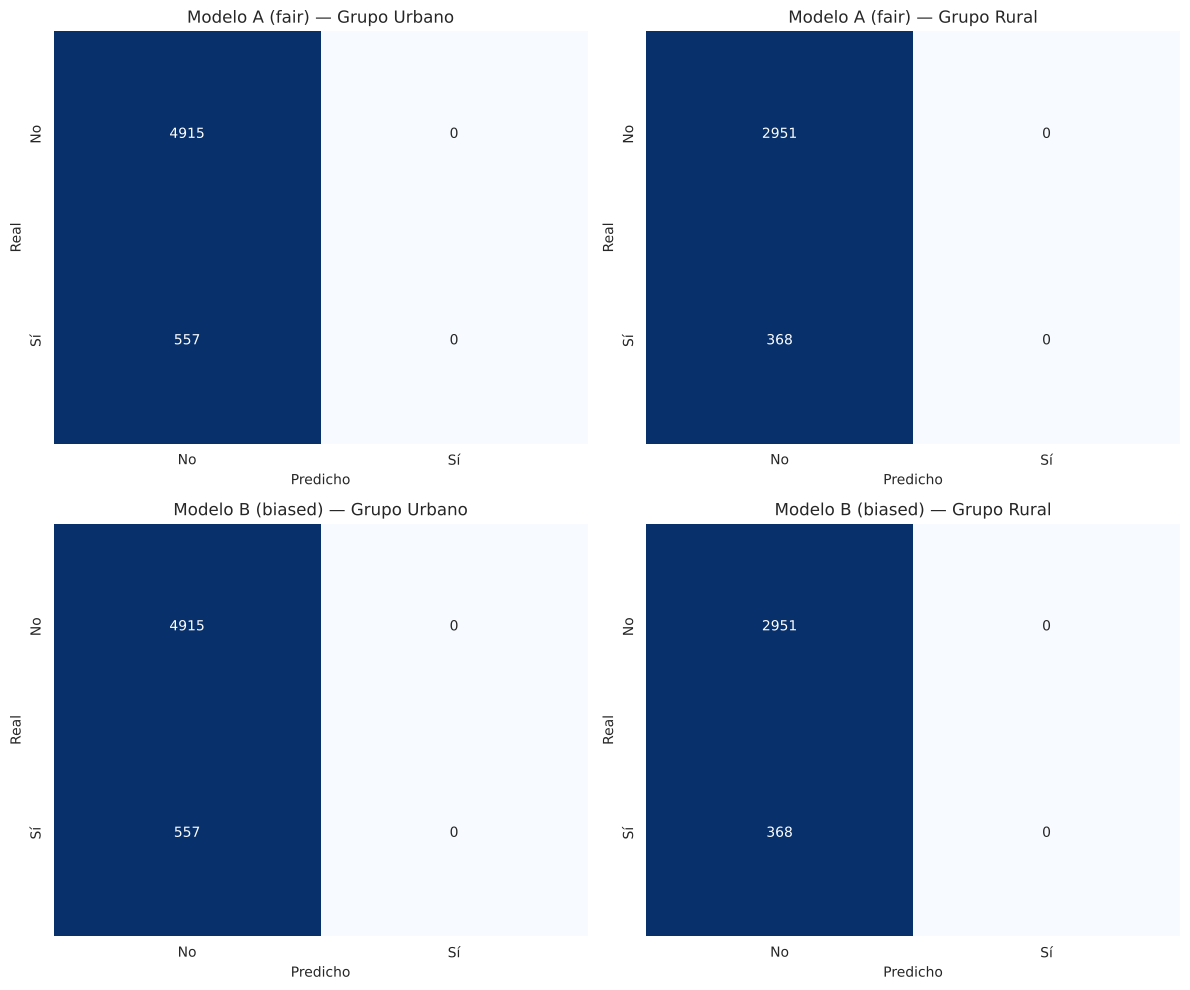

En las matrices se ve cómo el modelo sesgado comete más FN en el grupo minoritario.
Eso significa: menos escuelas minoritarias detectadas cuando realmente necesitan atención.


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (nombre, y_pred_m) in enumerate([('Modelo A (fair)', y_pred_fair),
                                        ('Modelo B (biased)', y_pred_biased)]):
    for j, grupo in enumerate([GRUPO_A, GRUPO_B]):
        mask = amb_test == grupo
        cm = confusion_matrix(y_test[mask], y_pred_m[mask], labels=[0, 1])
        cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        sns.heatmap(cm_norm, annot=cm, fmt='d', cmap='Blues', ax=axes[i, j],
                    xticklabels=['No', 'Sí'], yticklabels=['No', 'Sí'], cbar=False)
        axes[i, j].set_title(f'{nombre} — Grupo {grupo}')
        axes[i, j].set_xlabel('Predicho')
        axes[i, j].set_ylabel('Real')

plt.tight_layout()
plt.show()

print('En las matrices se ve cómo el modelo sesgado comete más FN en el grupo minoritario.')
print('Eso significa: menos escuelas minoritarias detectadas cuando realmente necesitan atención.')

## 7. Implicancias — qué está en juego

Si este modelo se usara para **priorizar recursos hacia escuelas en riesgo**,
el Modelo B (sesgado) dejaría sin apoyo a muchas escuelas rurales que realmente lo necesitan,
porque fue entrenado con pocas muestras de ese grupo y no aprendió bien sus patrones.

En dominios críticos como medicina, justicia, crédito o educación, **esto puede perpetuar
o amplificar inequidades históricas**.

### Caso real: COMPAS (EE.UU., 2016)
ProPublica mostró que COMPAS —un sistema usado para predecir reincidencia criminal—
tenía tasas de FP significativamente más altas para afroamericanos. Las métricas globales
de accuracy no revelaban esto. Solo apareció al desagregar por raza.

## 8. Resumen — dónde está el bias y cómo detectarlo

### Dónde aparece el bias
1. **Sampling bias**: algunos grupos subrepresentados en training
2. **Historical bias**: los datos históricos reflejan decisiones pasadas sesgadas
3. **Measurement bias**: el instrumento mide peor en algunos grupos (ej: acelerómetros en piel oscura)
4. **Survivorship bias**: solo ves casos que pasaron un filtro previo
5. **Proxy variables**: variables neutras que correlacionan con atributos protegidos

### Cómo diagnosticarlo
1. **Siempre desagregar** métricas por variables protegidas
2. Calcular **fairness metrics**: DP, EO, Equalized Odds
3. Matrices de confusión separadas por subgrupo
4. Buscar diferencias de TPR o FPR > 0.10 entre grupos

### Cómo mitigar
| Estrategia | Cuándo usar |
|---|---|
| Rebalanceo de training | Sampling bias claro |
| Reweighting (class_weight) | Simple, sin modificar datos |
| Fairness-constrained optimization | Cuando la equidad es requisito hard |
| Post-processing de threshold | Ajustar decisión por grupo |
| Remoción de variables proxy | Variables que codifican atributos protegidos |
| Herramientas: Fairlearn, AI Fairness 360 | Auditorías sistemáticas |

### Regla operativa
> **Una métrica global alta no garantiza un modelo justo.**
> 
> Cualquier modelo que afecte decisiones sobre personas o instituciones
> debe reportar métricas desagregadas por variables protegidas,
> incluso si no son usadas como features.

### Marco legal (breve)
- **GDPR (UE, 2018)**: exige no discriminación en decisiones automatizadas
- **EU AI Act (2024)**: obliga documentación de bias en sistemas de alto riesgo
- En Argentina: Ley 25.326 de protección de datos + marcos institucionales emergentes